# Week 3 — Iris Flower Clustering (K-Means & PCA)

**Dataset:** [Iris Dataset on Kaggle / UCI (`uciml/iris`)](https://www.kaggle.com/datasets/uciml/iris)

This notebook completes all Week 3 assignments and Mini Project 3 tasks:
1. **Assignment 1 & Mini Project 3**: Apply `KMeans(n_clusters=3)` to the Iris dataset, visualize clusters with scatter plots, and compare predicted clusters against true species labels.
2. **Assignment 2**: Apply `PCA` to reduce 4D floral features to 2D (`PC1`, `PC2`) and analyze explained variance.

In [1]:
import pandas as pd
from IPython.display import Image, display

from iris_clustering import (
    CLUSTERED_CSV_PATH,
    load_iris_dataset,
    plot_clusters_comparison,
    plot_pca_and_elbow_analysis,
    run_kmeans_and_pca,
)

## Load Dataset & Apply K-Means (k=3) + PCA (2D)

In [2]:
df_iris = load_iris_dataset()
print(f"Iris Dataset Shape: {df_iris.shape}")
display(df_iris.head())
display(df_iris.describe().round(2))

Iris Dataset Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00,150.00
mean,75.50,5.84,3.05,3.76,1.20
std,43.45,0.83,0.43,1.76,0.76
min,1.00,4.30,2.00,1.00,0.10
25%,38.25,5.10,2.80,1.60,0.30
50%,75.50,5.80,3.00,4.35,1.30
75%,112.75,6.40,3.30,5.10,1.80
max,150.00,7.90,4.40,6.90,2.50


In [3]:
res = run_kmeans_and_pca(df_iris, n_clusters=3)
print(f"PCA Explained Variance Ratio : {res['explained_variance_ratio']}")
print(f"PCA 2D Cumulative Variance   : {res['cumulative_variance_2d'] * 100:.2f}%")
print(f"Cluster-to-Species Mapping   : {res['cluster_to_species']}")
print(f"Silhouette Score (k=3)       : {res['silhouette_k3']:.4f}")
print(f"Adjusted Rand Index (ARI)    : {res['ari_score']:.4f}")
print(f"Normalized Mutual Info (NMI) : {res['nmi_score']:.4f}")
print(f"Matched Cluster Accuracy     : {res['matched_accuracy'] * 100:.2f}%")

CLUSTERED_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
res["df_clustered"].to_csv(CLUSTERED_CSV_PATH, index=False)
display(res["df_clustered"].head(10))

PCA Explained Variance Ratio : [0.7277, 0.2303, 0.0368, 0.0052]
PCA 2D Cumulative Variance   : 95.80%
Cluster-to-Species Mapping   : {1: 'Iris-setosa', 0: 'Iris-versicolor', 2: 'Iris-virginica'}
Silhouette Score (k=3)       : 0.5526
Adjusted Rand Index (ARI)    : 0.7302
Normalized Mutual Info (NMI) : 0.7582
Matched Cluster Accuracy     : 89.33%


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,PC1,PC2,Cluster,Predicted_Species,Is_Matched
0,1,5.1,3.5,1.4,0.2,Iris-setosa,-2.2645,0.5057,1,Iris-setosa,True
1,2,4.9,3.0,1.4,0.2,Iris-setosa,-2.0864,-0.6554,1,Iris-setosa,True
2,3,4.7,3.2,1.3,0.2,Iris-setosa,-2.3680,-0.3185,1,Iris-setosa,True
3,4,4.6,3.1,1.5,0.2,Iris-setosa,-2.3042,-0.5754,1,Iris-setosa,True
4,5,5.0,3.6,1.4,0.2,Iris-setosa,-2.3888,0.6748,1,Iris-setosa,True
5,6,5.4,3.9,1.7,0.4,Iris-setosa,-2.0705,1.5185,1,Iris-setosa,True
6,7,4.6,3.4,1.4,0.3,Iris-setosa,-2.4457,0.0746,1,Iris-setosa,True
7,8,5.0,3.4,1.5,0.2,Iris-setosa,-2.2338,0.2476,1,Iris-setosa,True
8,9,4.4,2.9,1.4,0.2,Iris-setosa,-2.3420,-1.0951,1,Iris-setosa,True
9,10,4.9,3.1,1.5,0.1,Iris-setosa,-2.1887,-0.4486,1,Iris-setosa,True


## Visualize K-Means Clusters vs. True Labels & PCA / Elbow Diagnostics

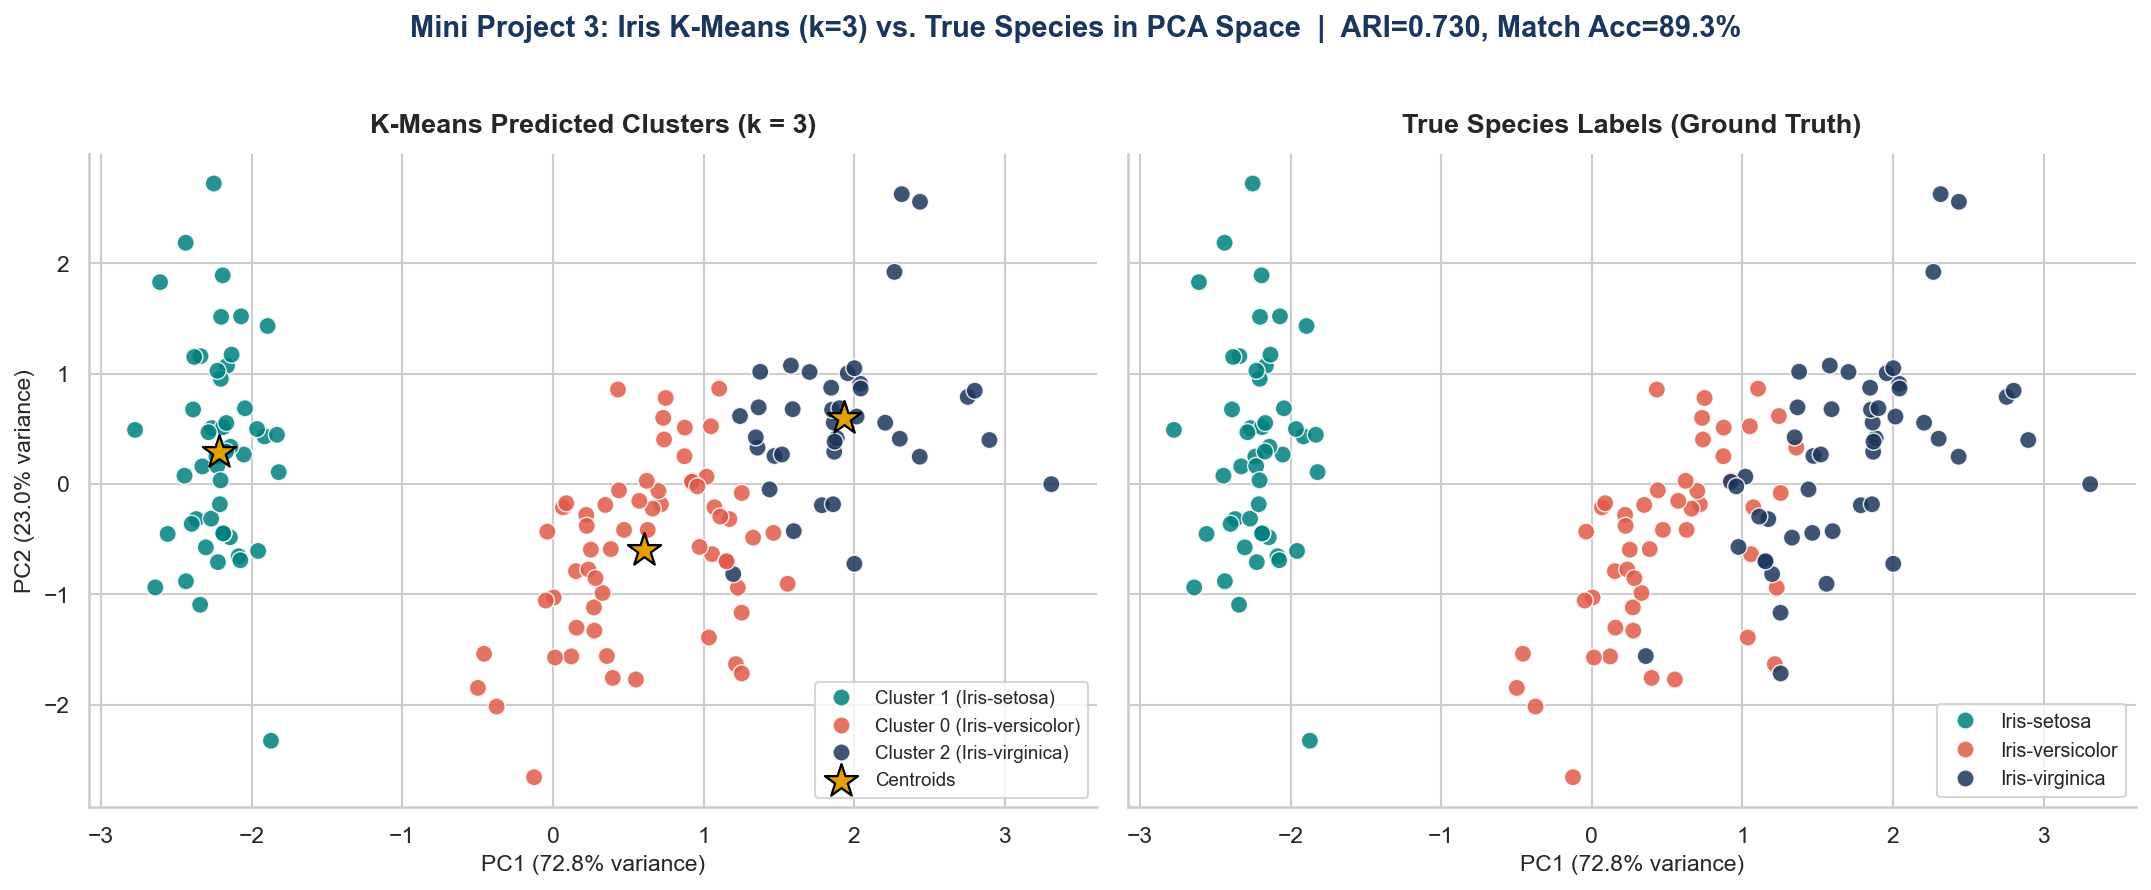

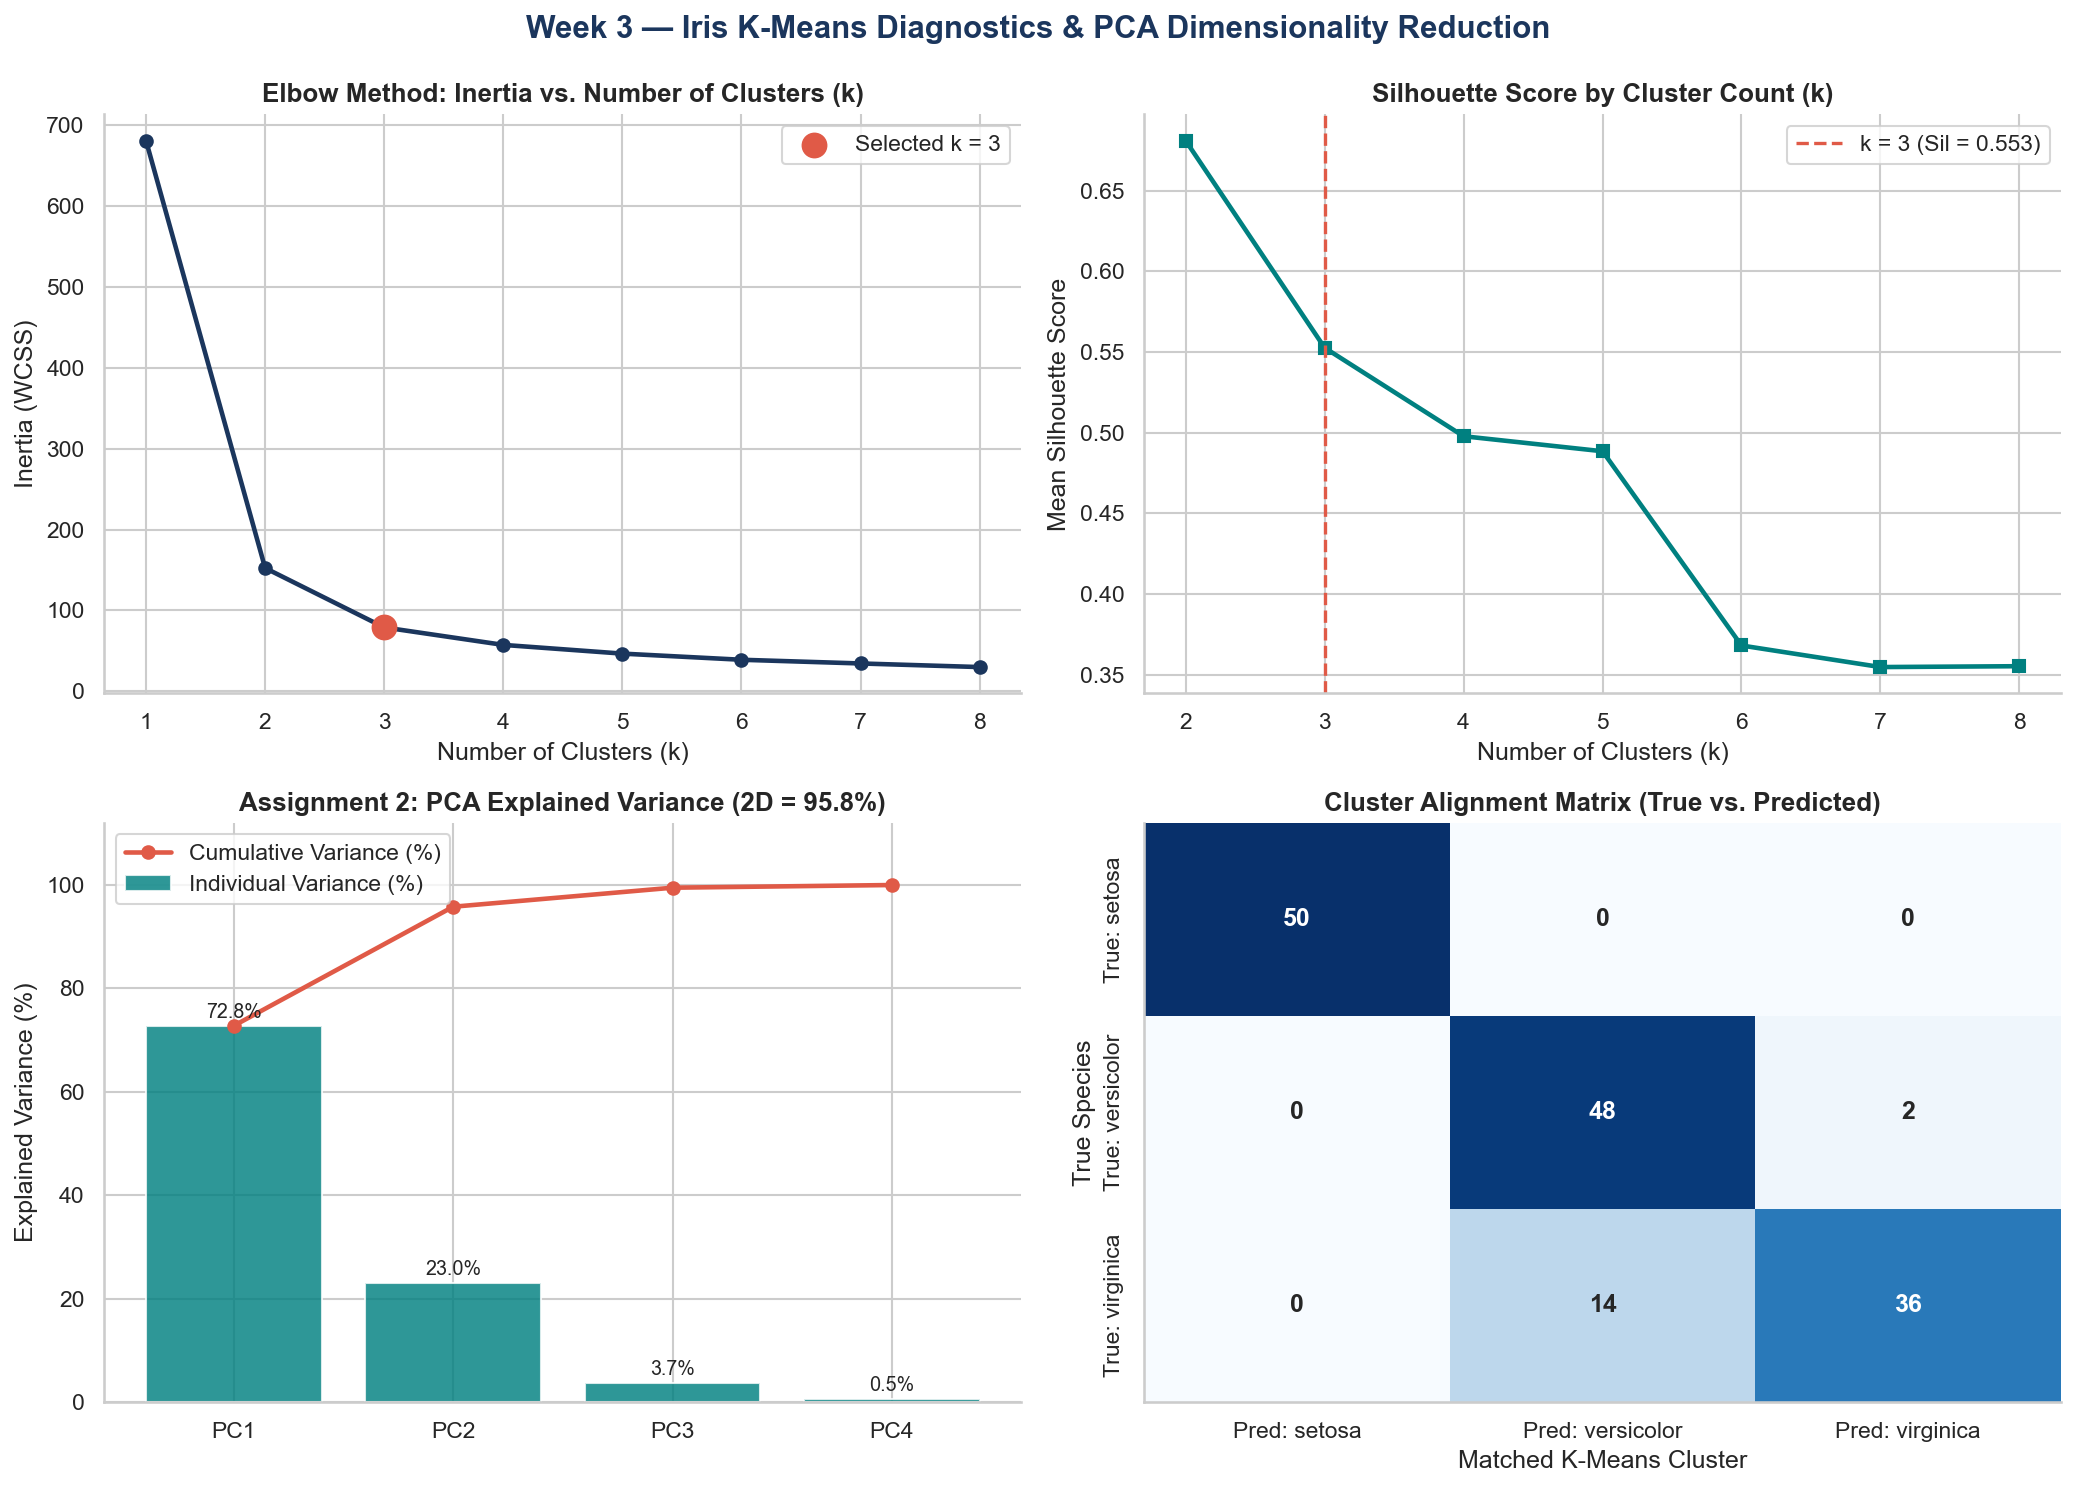

In [4]:
plot_clusters_comparison(res)
plot_pca_and_elbow_analysis(res)

display(Image(filename="outputs/iris_clusters_comparison.png"))
display(Image(filename="outputs/iris_pca_elbow_analysis.png"))